## Introduction to Flocking and Collective Dynamics
### Flocking is a common biological behavior seen in birds, insects, fish, and primates, 
### offering advantages like protection, coordination in feeding, and social interaction.
***

### Moving together requires coordination, not just proximity—organisms exhibit emergent 
### collective movement that isn't pre-programmed or gene-directed.
***
### The Vicsek model, introduced in the mid-1990s, offers a framework to study such 
### flocking behavior through local rules of interaction.
***
### In the model, each "boid" (self-propelled particle) updates its direction based 
### on the average direction of nearby neighbors within a radius r with some added randomness (noise).
***
### Emergent behavior can arise from these simple rules—random initial motion transitions 
### into coherent flock-like movement without central control.

***
### This transition resembles a phase transition, like water freezing into ice, 
### where local interactions lead to sudden, large-scale order across the system.
***
### Order is measured by an order parameter, which quantifies the alignment of 
### the entire group and grows dramatically once flocking emerges.
***
### The lab focuses on implementing and simulating the Vicsek model, exploring how simple interaction rules 
### can produce complex, population-wide patterns—capturing the beauty of 
### spontaneous symmetry breaking in nature.
*** 
## Vicsek (SPP) Model:

### A minimal model for simulating flocking behavior.
 
### Boids update their positions and directions based on their neighbors and some noise.

## Read through first section (9.1) on your own (5 min)


### **Vicsek Model Equations – Step by Step**


### 1. Initialization of Boid Position and Direction**

### Each boid $( i )$ at time $( t )$ has:

### - Position: $( (x_i(t), y_i(t)) )$  
### - Direction of motion: $( \theta_i(t) )$  
### - Constant speed: $( v_0 )$



### 2. Direction Update Rule (Orientation):**

### Each boid reorients based on the average direction of neighbors within radius \( R \):

### $$
\theta_i(t+1) = 
\arctan\left( 
\frac{ \langle \sin \theta_j(t) \rangle_R }{ \langle \cos \theta_j(t) \rangle_R }
\right)
+ \pi \cdot \Theta \left( -\langle \cos \theta_j(t) \rangle_R \right) + \text{noise}
$$

### Where:

### $$
\text{noise} \sim \text{Uniform} \left( -\frac{\eta}{2}, \frac{\eta}{2} \right)
$$



### 3. Position Update Rule (Ballistic Motion):**

### Each boid moves forward in the updated direction with constant speed:

### $$
x_i(t+1) = x_i(t) + v_0 \Delta t \cdot \cos\left( \theta_i(t+1) \right)
$$

### $$
y_i(t+1) = y_i(t) + v_0 \Delta t \cdot \sin\left( \theta_i(t+1) \right)
$$



### 4. Periodic Boundary Conditions (Wrap-Around):**

### If the boid moves outside the square domain of size \( L \):

### $$
x_i(t+1) \leftarrow x_i(t+1) \bmod L
$$

### $$
y_i(t+1) \leftarrow y_i(t+1) \bmod L
$$

### Positions wrap around a box of size  L×L


<div class="alert alert-block alert-warning">
<b>Challenge Problem: Reorienting Boids .</b> 
    
***
Write a code to reorient boids based on the orientation of neighbors, i.e., including both an averaging component
as well as a random term. Hint: identify a solution to the problem that arises in defining a local ‘group’ if the
focal boid is alone..
</div>

In [4]:
import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt

#Simulation Parameters 
N = 100       # Number of boids
L = 10.0      # Length of the domain (simulation box is L x L)
r = 1.0       # Radius of interaction (how far a boid "sees")
eta = 0.1     # Noise strength (how much randomness in their direction)

#Initialize Boid Positions and Directions 
currx = L * np.random.rand(N)             # Random x-positions between 0 and L
curry = L * np.random.rand(N)             # Random y-positions between 0 and L
currtheta = 2 * np.pi * np.random.rand(N) # Random orientation angles [0, 2π)

#Preallocate New Orientation Array 
newtheta = np.zeros(N)  # Stores updated directions after averaging + noise

#Reorient Each Boid Based on Its Neighbors 
for i in range(N):
    
    #  Compute Distance to All Other Boids (with Wrapping) 
    # Use the "minimum image convention" to compute the shortest distance on a periodic domain (torus)
    dx = np.minimum(np.abs(currx - currx[i]),np.minimum(np.abs(currx - (currx[i] + L)), np.abs(currx - (currx[i] - L))))
    dy = np.minimum(np.abs(curry - curry[i]),np.minimum(np.abs(curry - (curry[i] + L)), np.abs(curry - (curry[i] - L)) ) )

    # Combine into Euclidean distance
    boid_r2 = np.sqrt(dx**2 + dy**2)

    #  Identify Local Boids (Neighbors) 
    # Select the directions (theta) of boids within the sensing radius
    avgthetas = currtheta[boid_r2 <= r]

    #  Compute the Average Direction Using Vector Components 
    # Average unit vectors: convert angles to (cos, sin), then average, then convert back
    avgx = np.mean(np.cos(avgthetas))
    avgy = np.mean(np.sin(avgthetas))

    # Convert mean vector back to angle
    newtheta[i] = np.arctan2(avgy, avgx)
    
    # np.arctan(y/x) → basic arctangent, it cannot distinguish between vectors in opposite quadrants because it only sees the ratio y/x
    # np.arctan2(y, x) → two-argument arctangent, it considers the sign of both x and y to determine the correct quadrant of the angle.
    # effectively using heaviside
    
#Add Noise to Directions 
# Uniform noise added to each direction in the range [-η/2,$\eta$/2]
deltheta = -eta / 2 + eta * np.random.rand(N)

 


### The full simulation tracks:

### - x and y positions of each boid.

### - The direction of motion θ, over a total of  T time steps.

### The simulation starts by randomly placing each boid within a 2D domain.

### Each boid is assigned an initial velocity direction  θ chosen uniformly at random from the interval [0,2π].

### The goal is to implement a full Viscek/ SPP (Self-Propelled Particle) model using these initialization steps and update rules.

<div class="alert alert-block alert-warning">
<b>Challenge Problem: SPP Simulation Code .</b> 
    
***
Set-up the main code to initialize the dynamics and loop through time. A skeleton for the code is as follows.
The input parameters to this function are the total number of boids, N, the linear dimension of the domain,
L, and the amount of noise, η. Hint: implement the dynamics with periodic boundary conditions, but keep this
in mind while trying to detect which boids are close to each other.

</div>

In [7]:
def boids_dyn(pars):
    #Unpack simulation parameters from the dictionary 
    N = pars['N']           # Number of boids
    L = pars['L']           # Size of the domain (square of size L x L)
    eta = pars['eta']       # Noise strength (randomness in direction)
    delt = pars['delt']     # Time step size
    totsteps = pars['totsteps'] # Total number of time steps
    v0 = pars['v0']         # Speed of each boid (constant)
    r = pars['R']           # Sensing radius: how close other boids must be to count as neighbors

    #Initialize the position and direction of each boid 
    currx = L * np.random.uniform(size=N)             # x positions: random from 0 to L
    curry = L * np.random.uniform(size=N)             # y positions: random from 0 to L
    currtheta = 2 * np.pi * np.random.uniform(size=N) # orientations: random angle from 0 to 2π

    #Preallocate arrays to record the positions and directions over time 
    xt = np.zeros((totsteps, N))      # x trajectory over time
    yt = np.zeros((totsteps, N))      # y trajectory over time
    thetat = np.zeros((totsteps, N))  # direction (angle) over time

    #Start the simulation loop 
    for t in range(totsteps):
        newtheta = np.zeros(N)  # store new directions for all boids this step

        #  Loop through each boid 
        for i in range(N):
            #Compute distance to all other boids using periodic boundary conditions
            ## use np.minimum.reduce insetad of np.minimum!!!
            dx = np.minimum.reduce([
                np.abs(currx - currx[i]),          # normal distance
                np.abs(currx - (currx[i] + L)),    # wrapping forward
                np.abs(currx - (currx[i] - L))     # wrapping backward
            ])
            dy = np.minimum.reduce([
                np.abs(curry - curry[i]),
                np.abs(curry - (curry[i] + L)),
                np.abs(curry - (curry[i] - L))
            ])
            boid_r2 = np.sqrt(dx**2 + dy**2)  # Euclidean distance

            #Find all neighbors within radius r 
            neighbors = currtheta[boid_r2 <= r]  # Only use directions of nearby boids

            #Compute the average direction 
            avgx = np.mean(np.cos(neighbors))   # Average of x-components of headings
            avgy = np.mean(np.sin(neighbors))   # Average of y-components of headings
            newtheta[i] = np.arctan2(avgy, avgx) # Convert back to angle

        #Add noise to each boid's new direction 
        deltheta = -eta / 2 + eta * np.random.uniform(size=N)  # Uniform noise in [-η/2,$\eta$/2]
        currtheta = newtheta + deltheta                        # Update direction with noise
        
        #Update positions using constant-speed straight-line motion 
        currx = np.mod(currx + v0 * np.cos(currtheta) * delt, L)  # Wrap around domain (x)
        curry = np.mod(curry + v0 * np.sin(currtheta) * delt, L)  # Wrap around domain (y)

        #Store the state at this time step 
        xt[t, :] = currx
        yt[t, :] = curry
        thetat[t, :] = currtheta

    #Return the full trajectories 
    return xt, yt, thetat


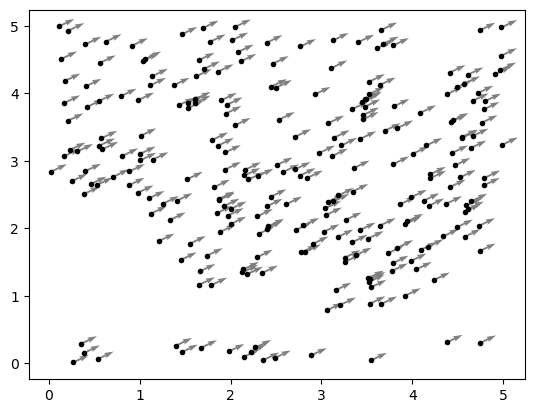

In [35]:
pars = {
    'N': 250,         # Number of boids
    'L': 5,          # Domain size
    'eta': 0.01,       # Noise level
    'delt': 0.2,        # Time step
    'totsteps': 1200, # Number of time steps
    'v0': 0.03,       # Constant speed
    'R': 0.5           # Interaction radius
}

xt, yt, thetat = boids_dyn(pars)

xt_final = xt[-1]
yt_final = yt[-1]
theta_final = thetat[-1]

vxt = np.cos(theta_final)
vyt = np.sin(theta_final)

plt.quiver(xt_final, yt_final, vxt, vyt, color='grey')
plt.plot(xt_final, yt_final, 'k.', linestyle='')


### Notice how the direction of boid movement can be different even if the boids are near each other
### The high noise causes deviations from the ordering.

### Boids (self-propelled particles) in the Vicsek model can behave very differently depending on noise level.

### We look at two regimes:

#### Low noise → boids tend to align and form flocks

#### High noise → movement is disorganized and random

### In the simulation above N = 250 boids in a 5x5 box with a speed of 0.03, time step of .2, and 1200 steps 

#### Low Noise : r = 0.5, eta = 0.1 --> flocks emerge, coherent motion
#### High Noise : r = 0.05, eta = 1 --> scattered, random movement

### Next challenge problem explores these different outcomes based on noise -> How the pattern changes over time given noise levels 
### Try it yourself and I will show how the patterns develop with low vs high noise

<div class="alert alert-block alert-warning">
<b>Challenge Problem: Visualizing the Flock.</b> 
    
***
Develop a visualization code that generates a panel of 16 images given a specified time set and positions and
velocities of each boid.

</div>

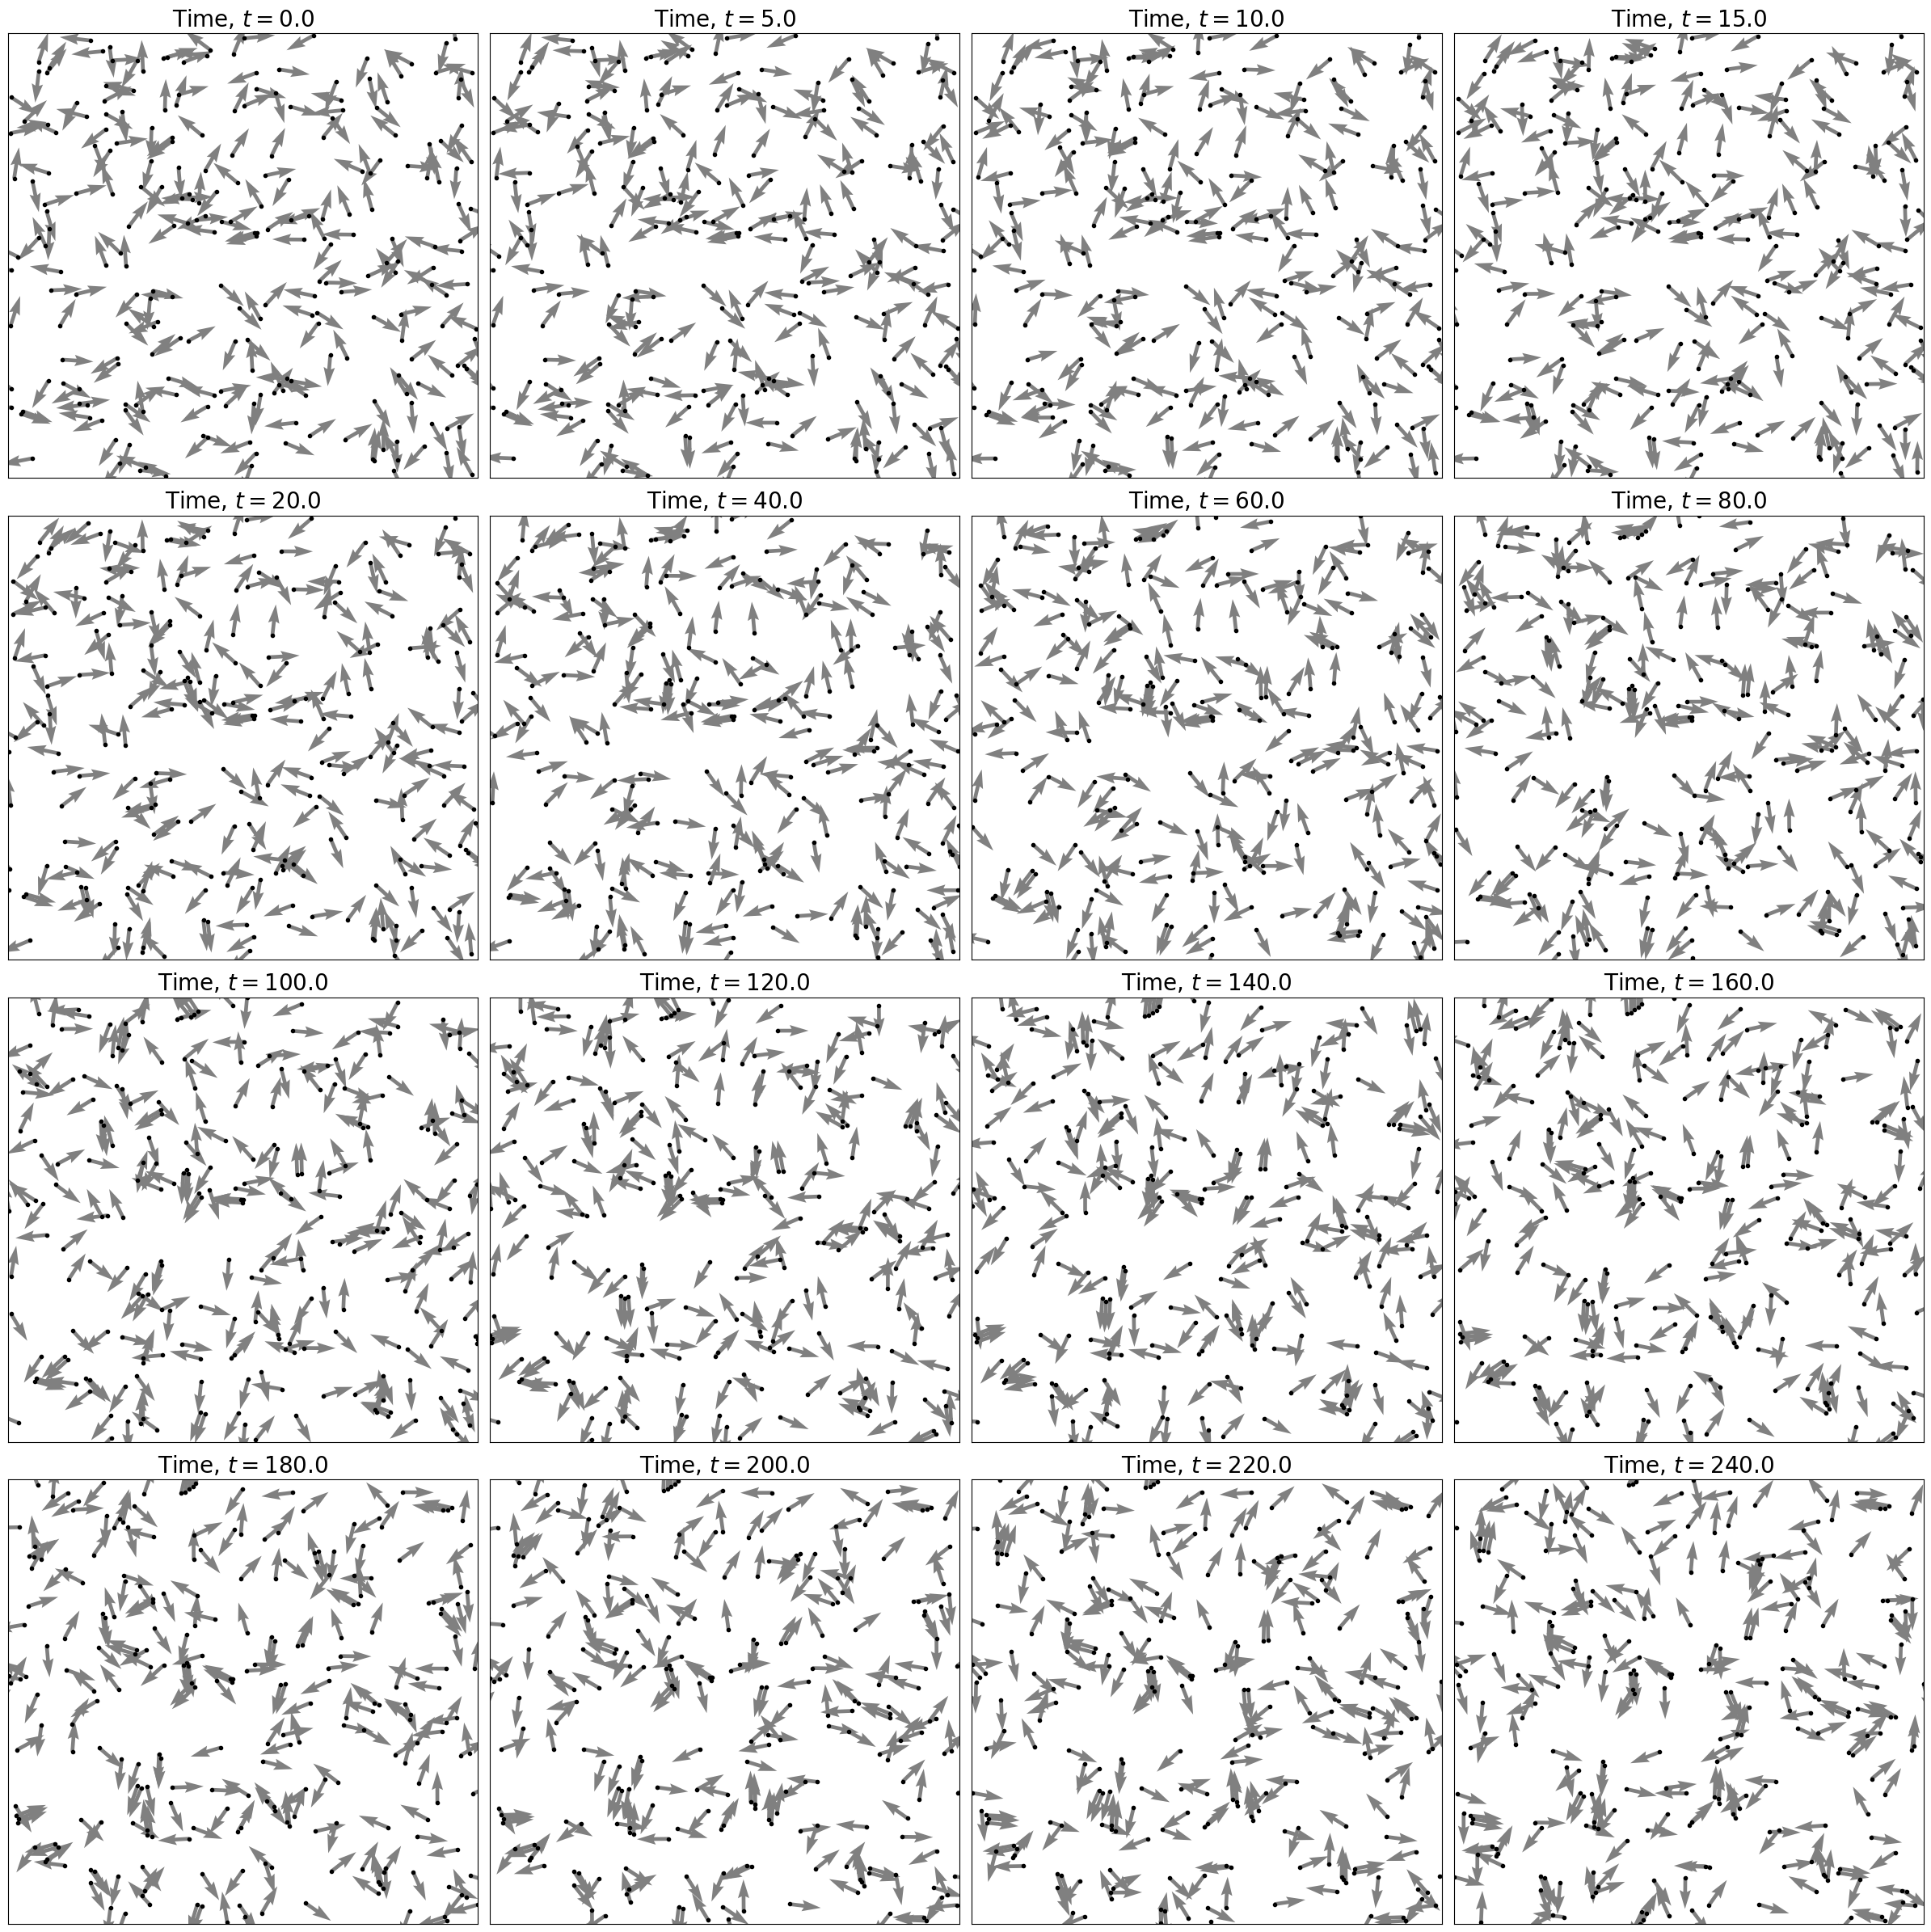

In [4]:
import numpy as np
import matplotlib.pyplot as plt

#  Simulation Parameters 
pars = {
    'N': 250,        # Number of boids
    'L': 100.0,        # Size of the domain
    'R': 1,        # Low Noise Interaction radius
    'eta': 0.1,      # Low Noise strength
    
    #'R': 0.05,      # High Noise Interaction radius
    #'eta': 1,       # High Noise strength
    
    'v0': 0.03,      # Speed
    'delt': 0.2,     # Time step
    'totsteps': 1201 # Total time steps
}

# Unpack parameters
N = pars['N']
L = pars['L']
r = pars['R']
eta = pars['eta']
v0 = pars['v0']
delt = pars['delt']
totsteps = pars['totsteps']

#  Initialize boid positions and orientations 
currx = L * np.random.rand(N)
curry = L * np.random.rand(N)
currtheta = 2 * np.pi * np.random.rand(N)

#  Preallocate arrays to store the simulation 
xt = np.zeros((totsteps, N))
yt = np.zeros((totsteps, N))
thetat = np.zeros((totsteps, N))

#  Simulate the dynamics over time 
for t in range(totsteps):
    newtheta = np.zeros(N)

    for i in range(N):
        # Periodic boundary condition distance calculation
        dx = np.minimum(np.abs(currx - currx[i]), np.abs(currx - (currx[i] + L)), np.abs(currx - (currx[i] - L)))
        dy = np.minimum(np.abs(curry - curry[i]), np.abs(curry - (curry[i] + L)), np.abs(curry - (curry[i] - L)))
        boid_r2 = np.sqrt(dx**2 + dy**2)

        # Find neighbors and average their orientations
        neighbors = currtheta[boid_r2 <= r]
        avgx = np.mean(np.cos(neighbors))
        avgy = np.mean(np.sin(neighbors))
        newtheta[i] = np.arctan2(avgy, avgx)

    # Add noise to the orientations
    deltheta = -eta/2 + eta * np.random.rand(N)
    currtheta = newtheta + deltheta

    # Update boid positions with ballistic motion
    currx = np.mod(currx + v0 * np.cos(currtheta) * delt, L)
    curry = np.mod(curry + v0 * np.sin(currtheta) * delt, L)

    # Save the current state
    xt[t, :] = currx
    yt[t, :] = curry
    thetat[t, :] = currtheta

#  Create a strip plot to visualize evolution 
nstrip = 16
tmpt = np.concatenate(([0, 25, 50, 75], np.arange(100, 1201, 100)))

fig = plt.figure(figsize=(24, 24))

for i in range(nstrip):
    ax = plt.subplot(4, 4, i+1)
    # Plot boid positions
    ax.plot(xt[tmpt[i], :], yt[tmpt[i], :], 'k.', linestyle='')
    # Plot direction arrows using quiver
    ax.quiver(xt[tmpt[i], :], yt[tmpt[i], :],
              np.cos(thetat[tmpt[i], :]), np.sin(thetat[tmpt[i], :]),
              color='grey', scale=15, width=0.008)
    # Add time label
    ax.set_title(f'Time, $t={tmpt[i]*pars["delt"]:.1f}$', fontsize=20)
    ax.set_xlim([0, L])
    ax.set_ylim([0, L])
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()


<div class="alert alert-block alert-warning">
<b>Challenge Problem: : Flock of Boids – The Movie.</b> 
    
***
Building upon the prior code, develop a movie version of your flock in a single panel, then watch it. It will be
particularly appealing if you use $\eta$= 0.25, r = 0.5, and N = 500.
</div>

### As you can see, flocking behavior develops when there is low noise while you see fairly scattered random movement over time with high noise 

### Will not run code below as it takes a while, but will show you the movies I got running it on PC at home


import matplotlib.animation as animation

def movie_dyn_save(xt, yt, thetat, pars, filename='cleanboids.mp4'):
    N = xt.shape[1]
    T = xt.shape[0]

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_xlim(0, pars['L'])
    ax.set_ylim(0, pars['L'])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect('equal')

    # Initialize with zeros (not empty lists)
    dots, = ax.plot(np.zeros(N), np.zeros(N), 'k.', markersize=3)
    quiver = ax.quiver(np.zeros(N), np.zeros(N), np.zeros(N), np.zeros(N), 
                       color='grey', scale=15, width=0.008)

    def init():
        dots.set_data([], [])
        quiver.set_offsets(np.zeros((N, 2)))
        quiver.set_UVC(np.zeros(N), np.zeros(N))
        return dots, quiver

    def update(i):
        dots.set_data(xt[i], yt[i])
        quiver.set_offsets(np.c_[xt[i], yt[i]])
        quiver.set_UVC(np.cos(thetat[i]), np.sin(thetat[i]))
        ax.set_title(f'Time Step {i}', fontsize=14)
        return dots, quiver

    ani = animation.FuncAnimation(fig, update, frames=T, init_func=init,
                                  interval=50, blit=True)

    ani.save(filename, writer='ffmpeg', fps=20)
    plt.close()

xt, yt, thetat = boids_dyn(pars)
movie_dyn_save(xt, yt, thetat, pars)

### What’s Happening?
### In this flocking model,$\eta$ (eta) controls the noise level — how randomly the boids (agents) move.

### Higher noise ($\eta$→ π) = boids move in random directions → no flocking behavior.

### Lower noise ($\eta$→ 0) = boids align their motion more → strong flocking or collective behavior.

### Measuring Order: The Order Parameter

### To measure how “ordered” or aligned the boids are, we use an order parameter, $\vec{v}$ which reflects how well the boids are moving in the same direction.

### $$
\vec{v} = \frac{1}{N v_0} \left| \sum_{i=1}^N \vec{v}_i \right|
$$

### This gives us a value between:

### 0 → No alignment (random directions)

### 1 → Perfect alignment (all boids move the same way)



In [16]:
def dyn2orderpar(thetat):
    N = len(thetat[0, :])               # Total number of boids (columns of thetat)
    
    # Compute x and y components of each boid's unit velocity vector
    vxt = np.cos(thetat)               # x-component of each boid's velocity
    vyt = np.sin(thetat)               # y-component of each boid's velocity

    # Sum velocity vectors across all boids at each time step
    sumvxt = np.sum(vxt, axis=1)       # shape (T,) – total x-velocity per time step
    sumvyt = np.sum(vyt, axis=1)       # shape (T,) – total y-velocity per time step

    # Calculate the magnitude of the average velocity (i.e., the order parameter)
    # This is the length of the average velocity vector over N boids
    normvt = np.sqrt(sumvxt**2 + sumvyt**2) / N  # shape (T,)

    return normvt


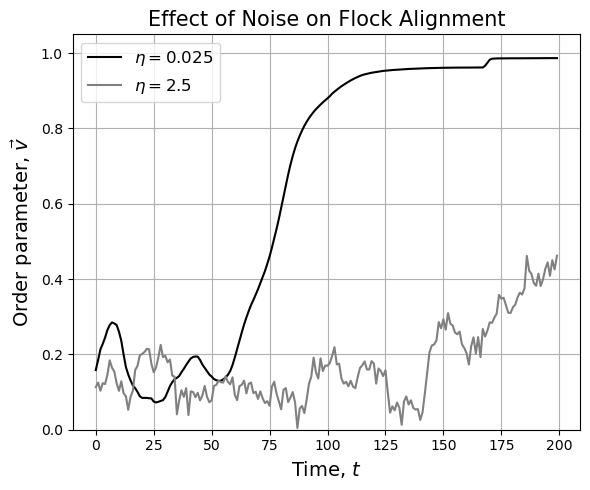

In [41]:
pars = {
    'N': 250,
    'L': 5,
    'v0': 0.03,
    'delt': 1.0,
    'totsteps': 200,
    'R': 0.3  # same radius for both
}

#  Simulate for eta = 0.25 (ordered case) 
pars_ordered = pars
pars_ordered['eta'] = 0.025
xt1, yt1, thetat1 = boids_dyn(pars_ordered)
order1 = dyn2orderpar(thetat1)

#  Simulate for eta = 2.5 (disordered case) 
pars_disordered = pars
pars_disordered['eta'] = 2.5
xt2, yt2, thetat2 = boids_dyn(pars_disordered)
order2 = dyn2orderpar(thetat2)

#  Plot the order parameter over time 
plt.figure(figsize=(6, 5))
plt.plot(order1, 'k-', label=r'$\eta = 0.025$')
plt.plot(order2, 'gray', label=r'$\eta = 2.5$')

plt.xlabel("Time, $t$", fontsize=14)
plt.ylabel(r"Order parameter, $\vec{v}$", fontsize=14)
plt.title("Effect of Noise on Flock Alignment", fontsize=15)
plt.ylim(0, 1.05)
plt.legend(fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()

### Low noise ($\eta$ = 0.25) leads to strong alignment: boids gradually synchronize their directions over time, causing the order parameter to rise close to 1 (strong flocking behavior).

### High noise ($\eta$ = 2.5) causes disorder: boids frequently change direction randomly, preventing sustained alignment — the order parameter remains low and fluctuates.

### The order parameter $\vec(v)$ measures collective alignment: it increases when boids move together, and drops when they move randomly.

### Conclusion: Lower noise promotes flocking and coordination, while higher noise disrupts it — a key feature of phase transitions in the Vicsek model.

<div class="alert alert-block alert-warning">
<b>Challenge Problem: : Coherence and Critical Levels of Noise</b> 
    
***
At what level of noise η does the final value of the order parameter drop nearly to 0? In doing so, use a density,
e.g., N = 300, r = 0.3, and a range of η from 0 to 5
</div>

/var/folders/bb/wr56q1rs761cp34pzwpk8r740000gn/T/ipykernel_20288/3272715943.py:32: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 1.05)


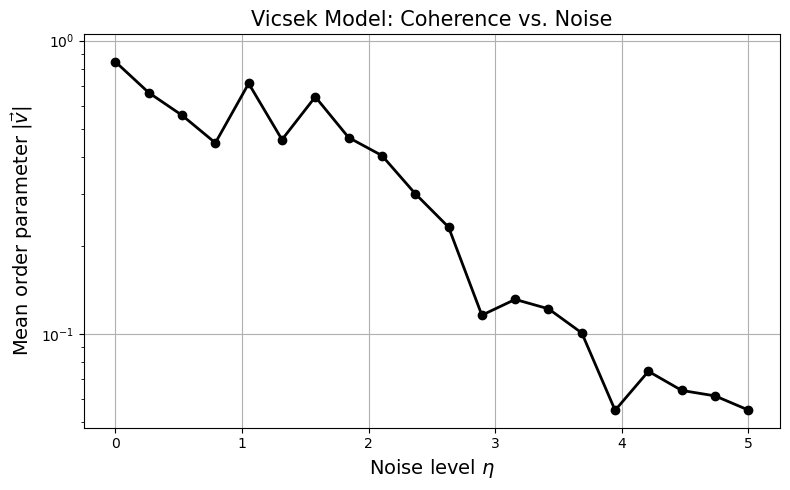

In [45]:
# Parameters
base_pars = {
    'N': 300,
    'L': 5.0,
    'v0': 0.03,
    'delt': 1.0,
    'totsteps': 200,
    'R': 0.3
}

eta_vals = np.linspace(0, 5, 20)
avg_order = np.zeros(len(eta_vals))

# Sweep over noise values
for i, eta in enumerate(eta_vals):
    pars = base_pars.copy()
    pars['eta'] = eta

    xt, yt, thetat = boids_dyn(pars)
    order_series = dyn2orderpar(thetat)

    # Ignore transient (first 50 steps)
    avg_order[i] = np.mean(order_series[50:])

# Plotting
plt.figure(figsize=(8, 5))
plt.semilogy(eta_vals, avg_order, 'ko-', linewidth=2, markersize=6)
plt.xlabel(r'Noise level $\eta$', fontsize=14)
plt.ylabel(r'Mean order parameter $|\vec{v}|$', fontsize=14)
plt.title('Vicsek Model: Coherence vs. Noise', fontsize=15)
plt.grid(True)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()


### When $\eta$ is low (i.e., noise is small), the order parameter $\vec{v}$ $\approx 1$
#### - The boids flock together with high alignment.

### As $\eta$ increases,  $\vec{v}$ decreases and drops to 0 near $\eta_c$ = 2.9
#### → The flock becomes disordered — boids move in random directions.

### This transition is not smooth — it appears sudden, like a phase change in physics.

### Consistent with Viscek's original 1995 study that says $\vec{v}$ $\sim$ $(\eta_c - \eta)^\beta$

### where $\beta$  critical exponent that describes how rapidly flocking breaks down near $\eta_c$

### If $\beta$ is small, flocking builds up quickly just below $\eta_c$ 
### If $\beta$ is large, flocking builds up slowly 

## Did calculations, and my $\beta$ for graph above is 0.56 -> moderate?